# Dos modelos finales y evaluación en test

Los modelos se entrenan desde cero con train/val y predicen el test 2024/25–2025/26 sin ningún ajuste adicional.

## Inicialización

Usamos la misma identidad de datos, código y protocolo en todos los cuadernos.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)
ROOT = Path.cwd()
while not (ROOT/'scripts/mlcore').is_dir():
    if ROOT == ROOT.parent: raise RuntimeError('No se encontro la raiz del proyecto')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'scripts'))
from mlcore.experiment import initialize, aligned
from mlcore.data import read_data, FOLDS, TEST
OUT = initialize()
print('Ejecucion verificada:', OUT.name)


Ejecucion verificada: 146e0afe9b28051c


**Qué encontramos y cómo se usa.** La identidad evita mezclar artefactos de protocolos distintos. Los cálculos científicos viven en `scripts/mlcore`; estos cuadernos explican, ejecutan y muestran cada etapa.

## Entrenamiento final y evaluación cerrada

Las decisiones se leen del archivo congelado. Si la misma ejecución ya fue evaluada, se leen sus resultados en lugar de volver a seleccionar.

In [2]:
from mlcore.experiment import evaluate
final=evaluate(OUT)
display(final)
display(pd.read_csv(OUT/'primary_comparisons.csv'))

,split,candidate,n,log_loss,RPS,Brier,AUC_macro,accuracy,balanced_accuracy,ECE_masa,ECE_ancho,acierto_ganador_condicional,recall_empate
0,validacion,prior,18184,1.071974,0.230953,0.648671,0.496274,0.437747,0.333333,0.013381,0.009633,0.582510,0.000000
1,validacion,consenso,18184,0.966435,0.195253,0.573667,0.684047,0.538440,0.463848,0.014312,0.012621,0.716575,0.000885
2,validacion,Pinnacle_respaldo,18184,0.965690,0.195084,0.573224,0.684675,0.538220,0.463744,0.013850,0.011183,0.716356,0.001328
3,validacion,modelo_con,18184,0.965199,0.194988,0.572867,0.684391,0.538715,0.464498,0.008538,0.006877,0.716795,0.001992
4,validacion,modelo_sin,18184,0.977711,0.198827,0.581429,0.671571,0.531071,0.454087,0.015587,0.014033,0.706696,0.000000
5,test,prior,5999,1.074963,0.229844,0.650572,0.500000,0.433072,0.333333,0.008585,0.008585,0.582642,0.000000
6,test,consenso,5999,0.966804,0.193444,0.574675,0.683804,0.538090,0.468773,0.022090,0.016843,0.723705,0.000649
7,test,Pinnacle_respaldo,5999,0.966263,0.193311,0.574416,0.683743,0.538090,0.468899,0.020755,0.015815,0.723929,0.001948
8,test,modelo_con,5999,0.965034,0.193014,0.573756,0.683438,0.538590,0.470351,0.016186,0.011806,0.724153,0.001948
9,test,modelo_sin,5999,0.979070,0.197491,0.583458,0.668145,0.524921,0.454535,0.012492,0.010829,0.706212,0.000000


,split,a,b,delta,lo,hi,p,temporadas_mejora,p_BH
0,validacion,modelo_con,consenso,-0.001236,-0.001955,-0.000500,0.002000,5/6,0.002500
1,validacion,modelo_con,Pinnacle_respaldo,-0.000491,-0.001085,0.000137,0.120776,5/6,0.120776
2,validacion,modelo_sin,consenso,0.011276,0.009188,0.013396,0.000400,0/6,0.000667
3,validacion,modelo_sin,Pinnacle_respaldo,0.012021,0.009887,0.014143,0.000400,0/6,0.000667
4,validacion,modelo_sin,modelo_con,0.012511,0.010381,0.014703,0.000400,0/6,0.000667
5,test,modelo_con,consenso,-0.001769,-0.002877,-0.000682,0.000800,2/2,0.001000
6,test,modelo_con,Pinnacle_respaldo,-0.001229,-0.002187,-0.000282,0.013197,2/2,0.013197
7,test,modelo_sin,consenso,0.012267,0.008527,0.016356,0.000400,0/2,0.000667
8,test,modelo_sin,Pinnacle_respaldo,0.012807,0.009033,0.016932,0.000400,0/2,0.000667
9,test,modelo_sin,modelo_con,0.014036,0.010007,0.018263,0.000400,0/2,0.000667


**Qué encontramos / decisión.** Ambos enfoques reciben evaluación sobre los mismos partidos. La identidad del test no se restaura borrando un modelo.

## Probabilidades, cuotas justas y backtest

La semejanza al mercado se calcula por referencia. La rentabilidad utiliza tau fijo y solo precios considerados fiables.

In [3]:
display(pd.read_csv(OUT/'similarity.csv'))
display(pd.read_csv(OUT/'backtest.csv'))
import joblib
df,sets=read_data(OUT); te=df[df.Season.isin(TEST)]
for branch in ['con','sin']:
    model=joblib.load(OUT/f'modelo_{branch}_cuotas.joblib'); p=model.predict_proba(te.iloc[:3])
    print(branch,'probabilidades',p,'cuotas justas',1/p)
    assert np.isfinite(p).all() and np.allclose(p.sum(1),1)

,split,reference,corr_logit,corr_pD,mismo_favorito,fraccion_ganancia_prior
0,validacion,consenso,0.947998,0.869265,0.908766,0.893160
1,validacion,Pinnacle_respaldo,0.947383,0.862073,0.908216,0.886899
2,test,consenso,0.949416,0.864975,0.909485,0.886587
3,test,Pinnacle_respaldo,0.948871,0.864675,0.909318,0.882177


,split,candidate,casa,tau,apuestas,ROI,lo,hi,EV_prometido
0,validacion,prior,B365,0.02,17159,-0.110958,-0.137723,-0.082515,0.891431
1,validacion,prior,PS,0.02,17798,-0.083434,-0.109931,-0.055974,0.947392
2,validacion,consenso,B365,0.02,809,0.253684,0.061971,0.458382,0.048979
3,validacion,consenso,PS,0.02,2039,-0.126719,-0.248057,0.001700,0.052877
4,validacion,Pinnacle_respaldo,B365,0.02,1509,0.074274,-0.053890,0.206302,0.056842
5,validacion,Pinnacle_respaldo,PS,0.02,0,NaN,NaN,NaN,NaN
6,validacion,modelo_con,B365,0.02,2578,0.064996,-0.016364,0.149800,0.057717
7,validacion,modelo_con,PS,0.02,3881,-0.041667,-0.103668,0.021341,0.042203
8,validacion,modelo_sin,B365,0.02,12320,-0.038050,-0.070138,-0.005056,0.161197
9,validacion,modelo_sin,PS,0.02,14932,-0.030332,-0.058233,0.000002,0.168975


con probabilidades [[0.70788611 0.18287659 0.1092373 ]
 [0.63610274 0.21746916 0.1464281 ]
 [0.33036703 0.29360995 0.37602303]] cuotas justas [[1.41265663 5.46816831 9.15438226]
 [1.57207308 4.59835319 6.82929038]
 [3.02693645 3.40587917 2.65941161]]


sin probabilidades [[0.58567716 0.25377824 0.1605446 ]
 [0.61652665 0.2405567  0.14291665]
 [0.30126975 0.28573535 0.41299489]] cuotas justas [[1.70742529 3.94044822 6.22879864]
 [1.62198989 4.15702411 6.99708555]
 [3.31928443 3.49974196 2.42133744]]


**Qué encontramos / decisión.** Las cuotas justas no incluyen margen comercial. Para usar el modelo deportivo se proporcionan sus variables históricas, nunca el resultado del partido.

## Entregables desde la misma tabla

Las figuras, el informe y las 13 diapositivas se generan desde esta ejecución, no desde cifras copiadas a mano.

In [4]:
from mlcore.report import render
render(OUT)
print('Fuentes de informe y presentacion regeneradas; compilar PDF con scripts/report/build.py')

Figuras, informe y 13 diapositivas actualizados desde 146e0afe9b28051c
Fuentes de informe y presentacion regeneradas; compilar PDF con scripts/report/build.py


**Qué encontramos / decisión.** Las conclusiones de ambas ramas deben seguir los resultados corregidos. La siguiente evaluación independiente requiere partidos futuros.

## Resultados por temporada y por liga

Desglosamos el log loss de los dos modelos finales y de las referencias para ver si el resultado global se repite en cada temporada y en cada liga.

In [5]:
bs = pd.read_csv(OUT/'by_season.csv').pivot(index='Season', columns='candidate', values='log_loss')[['prior', 'consenso', 'Pinnacle_respaldo', 'modelo_con', 'modelo_sin']]
display(bs.round(4)); bl = pd.read_csv(OUT/'by_league.csv')
for split in bl.split.unique():
    t = bl[bl.split.eq(split)].pivot(index='Div', columns='candidate', values='log_loss')[['consenso', 'modelo_con', 'modelo_sin']]
    t['con − consenso'] = t.modelo_con-t.consenso; t['sin − consenso'] = t.modelo_sin-t.consenso
    print(split, '· ligas donde el modelo con cuotas mejora al consenso:', int((t['con − consenso'] < 0).sum()), 'de', len(t)); display(t.round(4))

candidate,prior,consenso,Pinnacle_respaldo,modelo_con,modelo_sin
Season,,,,,
1819,1.0645,0.9594,0.9592,0.9588,0.9729
1920,1.0672,0.9732,0.9726,0.9722,0.9850
2021,1.0880,0.9855,0.9854,0.9865,1.0002
2122,1.0754,0.9703,0.9694,0.9686,0.9831
2223,1.0609,0.9613,0.9601,0.9599,0.9660
2324,1.0747,0.9486,0.9471,0.9449,0.9588
2425,1.0738,0.9584,0.9573,0.9566,0.9730
2526,1.0762,0.9754,0.9754,0.9736,0.9852


validacion · ligas donde el modelo con cuotas mejora al consenso: 8 de 9


candidate,consenso,modelo_con,modelo_sin,con − consenso,sin − consenso
Div,,,,,
B1,0.9827,0.9811,0.9966,-0.0016,0.0139
D1,0.9756,0.9736,0.9864,-0.0019,0.0109
E0,0.9473,0.9470,0.9572,-0.0003,0.0099
F1,0.9965,0.9972,1.0145,0.0008,0.0180
I1,0.9606,0.9603,0.9754,-0.0003,0.0148
N1,0.9225,0.9221,0.9331,-0.0004,0.0107
P1,0.9230,0.9189,0.9330,-0.0041,0.0100
SP1,0.9823,0.9811,0.9919,-0.0012,0.0096
T1,0.9999,0.9973,1.0037,-0.0026,0.0038


test · ligas donde el modelo con cuotas mejora al consenso: 6 de 9


candidate,consenso,modelo_con,modelo_sin,con − consenso,sin − consenso
Div,,,,,
B1,1.0078,1.0069,1.0191,-0.0009,0.0114
D1,0.9717,0.9719,0.9802,0.0003,0.0085
E0,0.9940,0.9953,1.0121,0.0013,0.0181
F1,0.9660,0.9665,0.9796,0.0005,0.0136
I1,0.9674,0.9635,0.9806,-0.0039,0.0132
N1,0.9622,0.9585,0.9722,-0.0037,0.0100
P1,0.9243,0.9208,0.9251,-0.0035,0.0008
SP1,0.9590,0.9576,0.9703,-0.0014,0.0113
T1,0.9447,0.9399,0.9662,-0.0048,0.0216


**Qué encontramos / decisión.** El modelo con cuotas queda por debajo del consenso en siete de las ocho temporadas (la excepción es 2020/21) y el modelo sin cuotas queda por encima del mercado en todas. Por liga, el modelo con cuotas mejora al consenso en ocho de nueve en validación y en seis de nueve en test: la mejora global no se reparte por igual, y en Inglaterra, Alemania y Francia el test no la muestra.

## Calibración de los modelos finales en el test

Repetimos el diagrama de calibración con las predicciones del test, solo para describirlas: no se ajusta nada con este resultado.

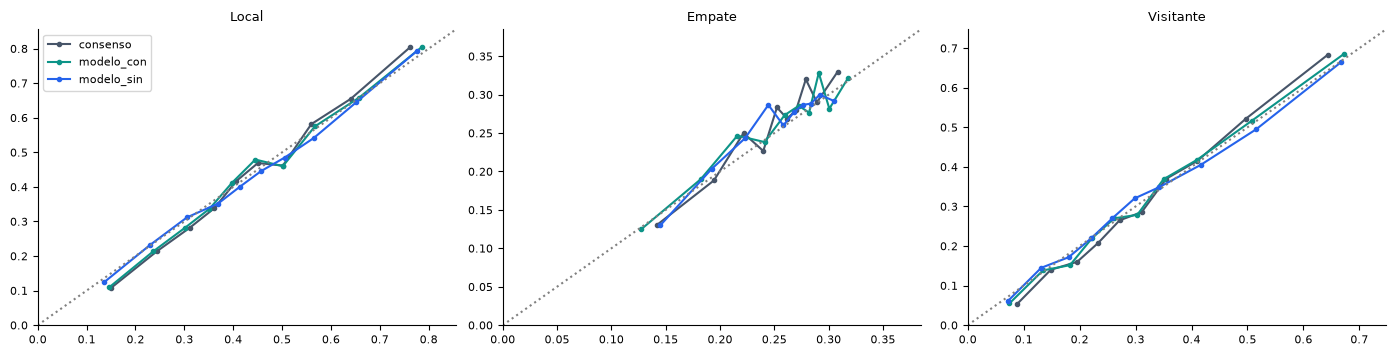

clase,A,D,H
serie,,,
consenso,0.0220,0.0170,0.0272
modelo_con,0.0139,0.0136,0.0211
modelo_sin,0.0109,0.0136,0.0130


In [6]:
%matplotlib inline
from mlcore.metrics import ece
tp = pd.read_csv(OUT/'test_predictions.csv'); te = df[df.Season.isin(TEST)]; fig, axes = plt.subplots(1, 3, figsize=(14, 3.6)); rows = []
for j, ax in enumerate(axes):
    for name, color in [('consenso', '#475569'), ('modelo_con', '#0d9488'), ('modelo_sin', '#2563eb')]:
        p = aligned(tp, name, te)[:, j]; g = pd.DataFrame({'p': p, 'o': te.y.eq(j).to_numpy()}); g['bin'] = pd.qcut(g.p, 10, duplicates='drop'); t = g.groupby('bin', observed=True)[['p', 'o']].mean()
        ax.plot(t.p, t.o, 'o-', color=color, ms=3, label=name); rows.append(dict(serie=name, clase='HDA'[j], ECE=ece(p, te.y.eq(j))))
    ax.plot([0, 1], [0, 1], ':', color='gray'); ax.set_title(['Local', 'Empate', 'Visitante'][j]); ax.set_xlim(0, t.p.max()+.08); ax.set_ylim(0, t.p.max()+.08)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show(); display(pd.DataFrame(rows).pivot(index='serie', columns='clase', values='ECE').round(4))

**Qué encontramos / decisión.** En el test el modelo con cuotas vuelve a estar mejor calibrado que el consenso en las tres clases (por ejemplo, 0,021 frente a 0,027 en victoria local). El modelo sin cuotas tiene aquí el menor ECE agregado; eso no significa que prediga mejor, porque su log loss es mayor: está bien calibrado, pero distingue peor unos partidos de otros.

## Reglas de decisión para el empate

El experimento adicional de empates cambia la regla con la que se elige la clase. Mostramos el modelo original y la regla elegida en cada enfoque.

In [7]:
dr = pd.read_csv(ROOT/'docs/resultados_empates.csv')
display(dr[dr.family.isin(['base', 'boost', 'detector_threshold'])][['split', 'branch', 'family', 'log_loss', 'F1_macro', 'accuracy', 'recall_D', 'precision_D']].round(4))

,split,branch,family,log_loss,F1_macro,accuracy,recall_D,precision_D
0,test,con,base,0.9650,0.4046,0.5386,0.0019,0.5000
1,test,con,boost,0.9650,0.4822,0.5048,0.3610,0.2996
3,test,con,detector_threshold,0.9658,0.4831,0.4956,0.4299,0.3044
8,test,sin,base,0.9791,0.3902,0.5249,0.0000,0.0000
9,test,sin,boost,0.9791,0.4649,0.4749,0.4747,0.2901
11,test,sin,detector_threshold,0.9802,0.4731,0.4856,0.3961,0.2951
16,validacion,con,base,0.9652,0.4021,0.5387,0.0020,0.4500
17,validacion,con,boost,0.9652,0.4845,0.5093,0.3642,0.3011
19,validacion,con,detector_threshold,0.9656,0.4854,0.5018,0.4240,0.3074
24,validacion,sin,base,0.9777,0.3925,0.5311,0.0000,0.0000


**Qué encontramos / decisión.** Las reglas de decisión suben el F1 macro (de 0,40 a 0,48 con cuotas y de 0,39 a 0,47 sin cuotas) y llevan el recall del empate a 36–40 %, a cambio de 3 a 4 puntos de accuracy. La regla elegida con cuotas (multiplicar la probabilidad de empate) no cambia el log loss; la elegida sin cuotas (el detector con umbral) lo empeora ligeramente. Son reglas para elegir etiqueta, no mejores probabilidades.